In [1]:
print("shubham jadav")

shubham jadav


In [ ]:
pip install numpy pandas matplotlib seaborn 

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement openxl (from versions: none)

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for openxl


In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_excel("Superstore_Sales_Practice_Dataset.xlsx")

print(df)

       Order ID Order Date Customer ID   Customer Name      Segment   Region  \
0     ORD-00001 2023-05-23   CUST-0016    Taylor Brown     Consumer     East   
1     ORD-00002 2024-10-27   CUST-0082   Skyler Martin    Corporate     West   
2     ORD-00003 2023-12-11   CUST-0023  Rowan Thompson  Home Office  Central   
3     ORD-00004 2024-09-25   CUST-0041    Jamie Taylor    Corporate     East   
4     ORD-00005 2024-01-09   CUST-0037   Dakota Walker    Corporate     East   
...         ...        ...         ...             ...          ...      ...   
1495  ORD-01496 2024-07-26   CUST-0065    Jordan Davis  Home Office    South   
1496  ORD-01497 2023-05-21   CUST-0005  Parker Jackson  Home Office  Central   
1497  ORD-01498 2023-01-31   CUST-0167     Quinn White     Consumer     West   
1498  ORD-01499 2023-08-26   CUST-0171     Quinn White     Consumer     West   
1499  ORD-01500 2023-09-13   CUST-0242    Jamie Taylor     Consumer     West   

               State         City      

In [4]:
df.head(5)

,Order ID,Order Date,Customer ID,Customer Name,Segment,Region,State,City,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,ORD-00001,2023-05-23,CUST-0016,Taylor Brown,Consumer,East,New York,New York,Technology,Copiers,4613.96,12,0.05,28.14
1,ORD-00002,2024-10-27,CUST-0082,Skyler Martin,Corporate,West,Washington,Seattle,Technology,Phones,2229.47,12,0.40,-195.20
2,ORD-00003,2023-12-11,CUST-0023,Rowan Thompson,Home Office,Central,Minnesota,Minneapolis,Furniture,Tables,386.58,2,0.05,28.33
3,ORD-00004,2024-09-25,CUST-0041,Jamie Taylor,Corporate,East,New York,Buffalo,Furniture,Bookcases,3023.22,6,0.15,-168.36
4,ORD-00005,2024-01-09,CUST-0037,Dakota Walker,Corporate,East,New York,Buffalo,Office Supplies,Labels,102.84,3,0.30,-18.01


In [ ]:
df["Month"] = df["Order Date"].dt.to_period("M") 

# group ma sales karis 
monthly_sales = df.groupby("Month")["Sales"].sum()

print(monthly_sales)

Month
2023-01    101940.52
2023-02     76859.21
2023-03     89166.52
2023-04    122642.92
2023-05    140034.35
2023-06    106182.18
2023-07     90492.55
2023-08     79703.39
2023-09     75287.19
2023-10     96437.17
2023-11    119875.16
2023-12     93253.48
2024-01    103777.32
2024-02     92513.49
2024-03    100876.87
2024-04     86608.54
2024-05     97594.57
2024-06     71940.47
2024-07     79358.88
2024-08    117712.83
2024-09     99076.33
2024-10    129378.36
2024-11    104656.68
2024-12    114085.94
Freq: M, Name: Sales, dtype: float64


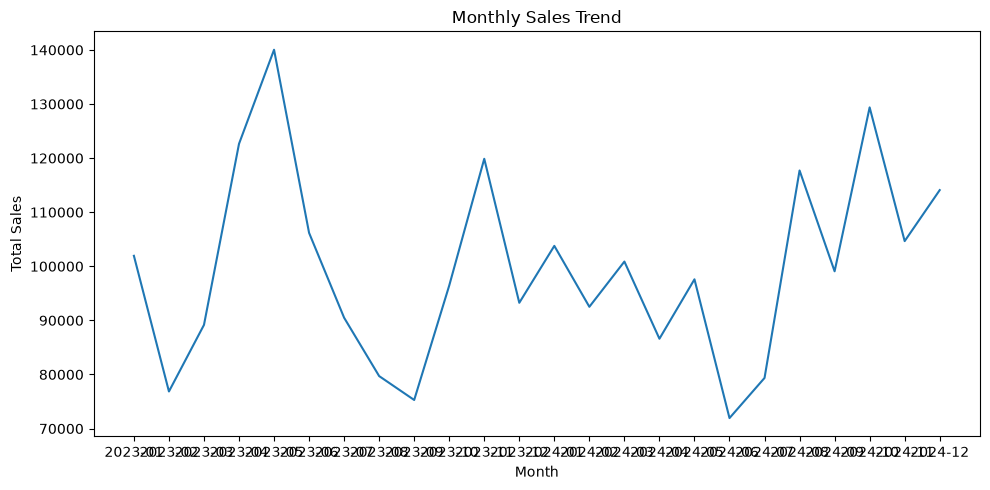

In [27]:
# Task 1

high_sales = monthly_sales.max()

high_month = monthly_sales.idxmax()
plt.figure(figsize=(10,5))

plt.plot(monthly_sales.index.astype(str),monthly_sales.values)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

Category
Furniture           726984.48
Office Supplies     223990.42
Technology         1438480.02
Name: Sales, dtype: float64


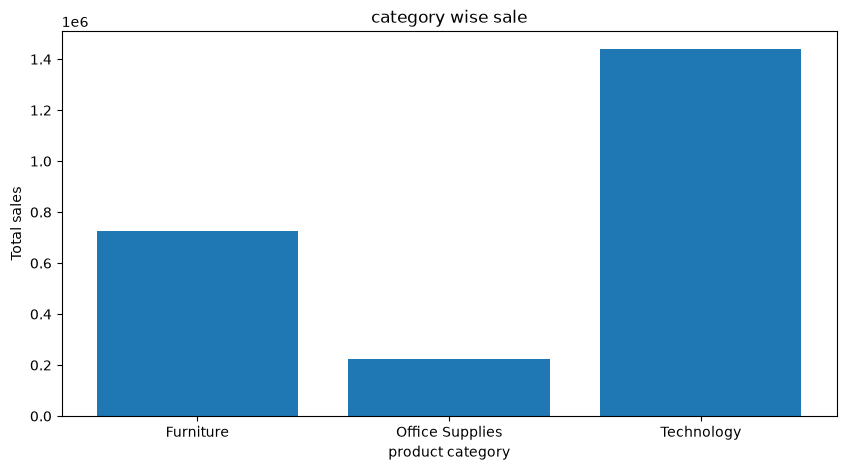

In [11]:
# task 2 : Category-wise Sales Comparison: Calculate total sales for each product category and create a customized bar chart with sales values displayed on top of each bar.

category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales)

plt.figure(figsize=(10,5))

plt.bar(category_sales.index,category_sales.values)

plt.title("category wise sale")
plt.xlabel("product category")
plt.ylabel("Total sales")
plt.show()

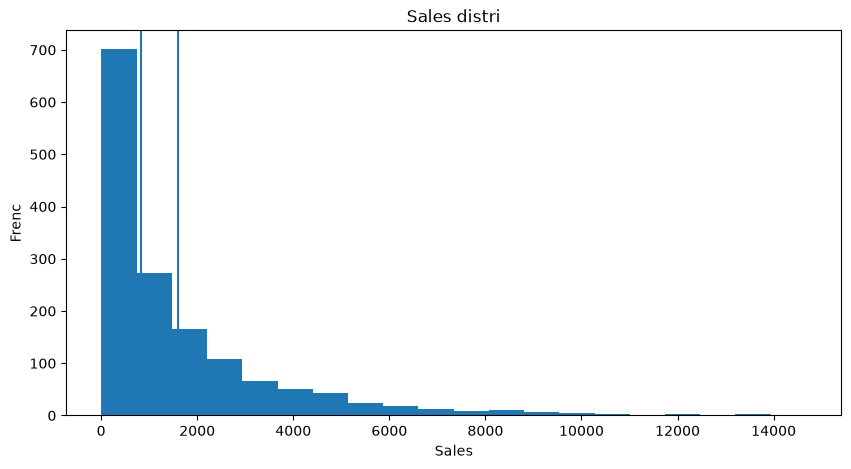

In [13]:
# task 3 : Sales Distribution Analysis: Create a histogram of the Sales column with 20 bins. Display mean and median using vertical reference lines and analyze the distribution.

sales_mean = df["Sales"].mean()
sales_median = df["Sales"].median()


plt.figure(figsize=(10,5))

plt.hist(df["Sales"],bins=20)

plt.axvline(sales_mean,label="mean")

plt.axvline(sales_median,label="Mean")

plt.title("Sales distri")
plt.xlabel("Sales")
plt.ylabel("Frenc")

plt.show()


In [14]:
#task 4 : Region sales 
reg_sales = df.groupby("Region")["Sales"].sum()

reg_profit = df.groupby("Region")["Profit"].sum()

df["Month"] = df["Order Date"].dt.to_period("M")



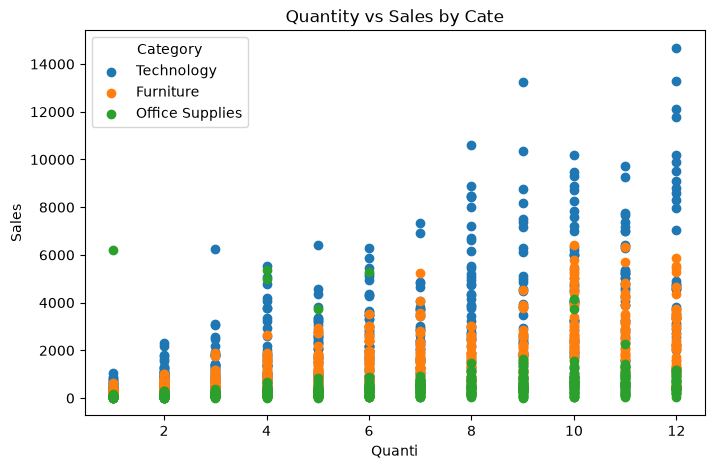

In [16]:
# task 5 : scctter plot 

plt.figure(figsize=(8,5))

for category in df["Category"].unique():

    category_data = df[df["Category"] == category]

    plt.scatter(category_data["Quantity"],
                category_data["Sales"],
                label=category)

plt.title("Quantity vs Sales by Cate")
plt.xlabel("Quanti")
plt.ylabel("Sales")
plt.legend(title="Category")

plt.show()

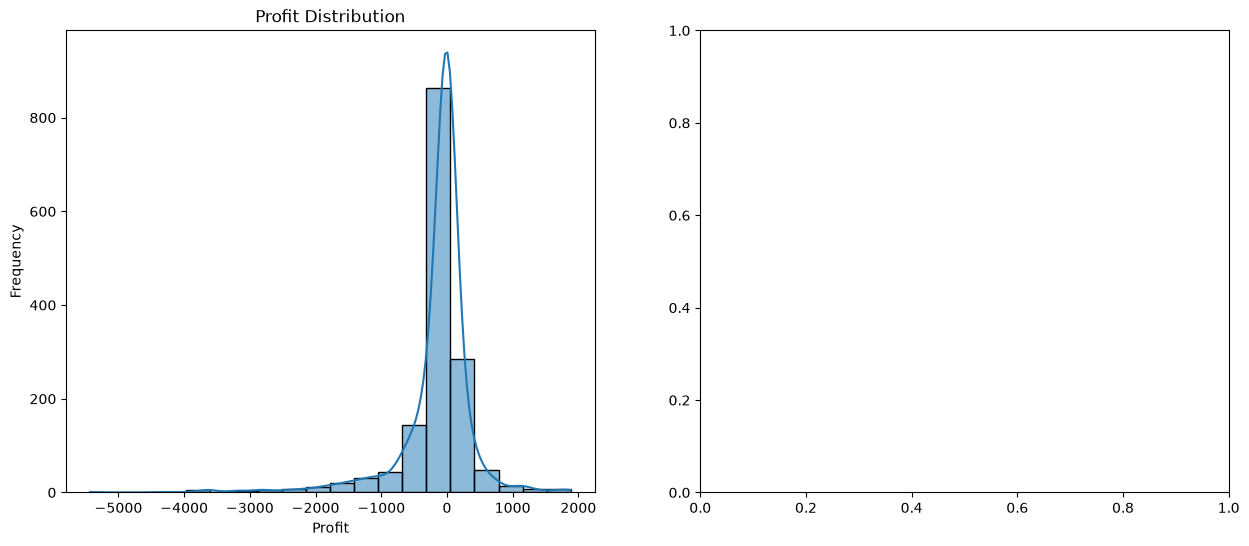

In [ ]:
# task 6 Sale vs profit sebaorn 

fig,ax = plt.subplots(1,2, figsize=(15,6))



#profit dist 
sns.histplot(data=df, x="Profit", bins=20, kde=True, ax=ax[0])

ax[0].set_title("Profit Distribution")
ax[0].set_xlabel("Profit")
ax[0].set_ylabel("Frequency")

# sales dirt
sns.histplot(data=df, x="Sales", bins=20, kde=True, ax=ax=[1])

#ax[1].set_title("Sales Distri")
#ax[1].set_xlabel("Sales")
#ax[1].set_ylabel("Frequency")

plt.show()

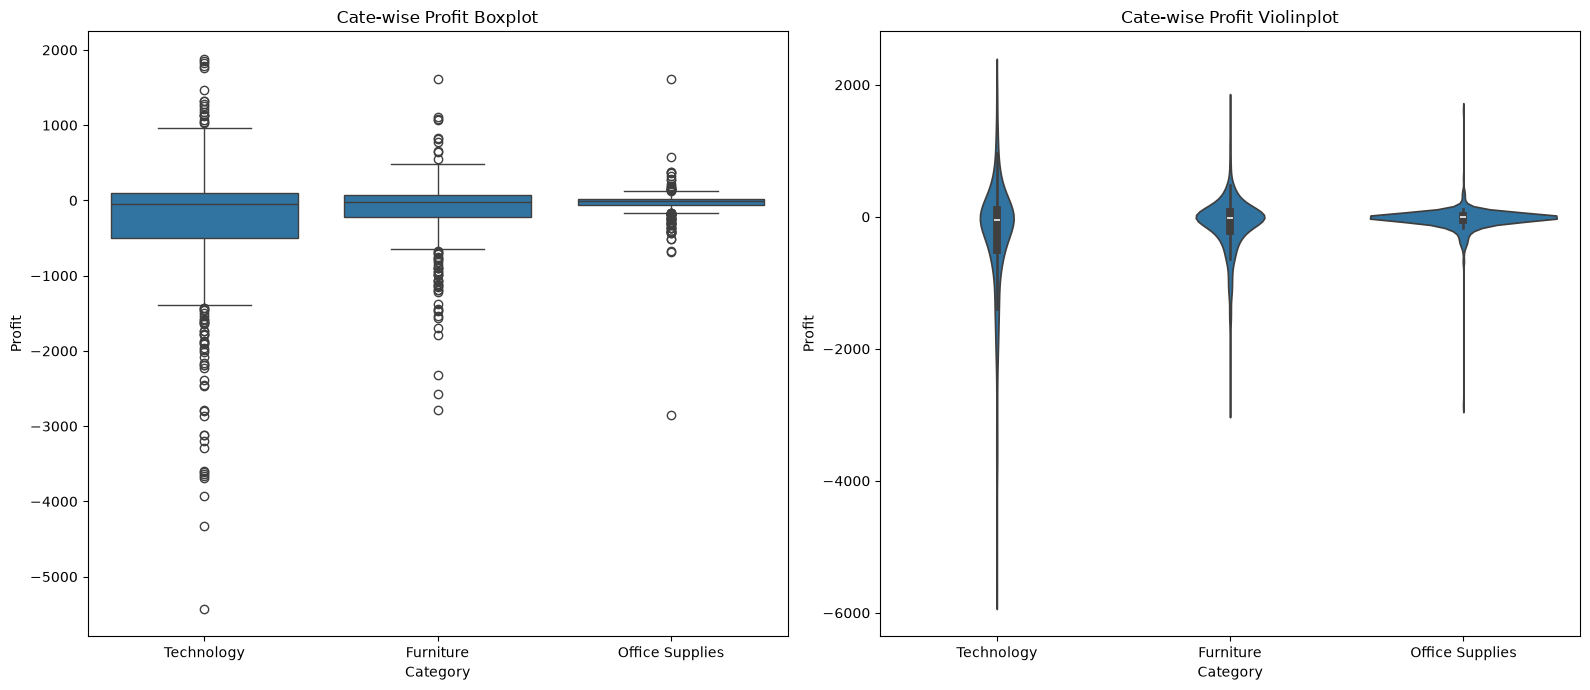

In [30]:
# task 7 
fig, ax = plt.subplots(1, 2, figsize=(16, 7))


sns.boxplot(data=df, x="Category", y="Profit", ax=ax[0])

ax[0].set_title("Cate-wise Profit Boxplot")
ax[0].set_xlabel("Category")
ax[0].set_ylabel("Profit")

sns.violinplot(data=df, x="Category", y="Profit", ax=ax[1])

ax[1].set_title("Cate-wise Profit Violinplot")
ax[1].set_xlabel("Category")
ax[1].set_ylabel("Profit")

plt.tight_layout()
plt.show()



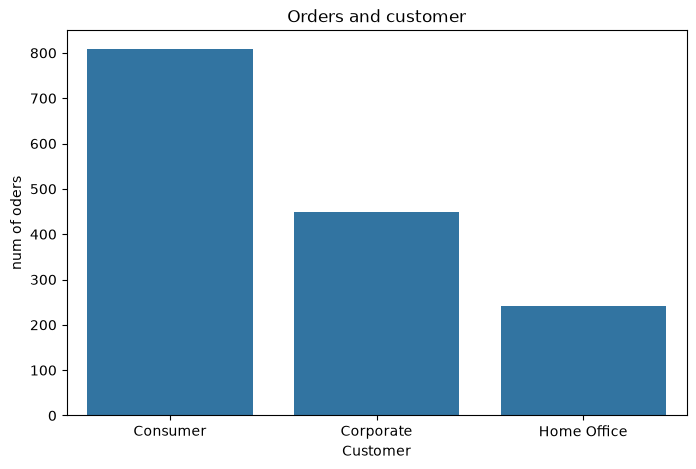

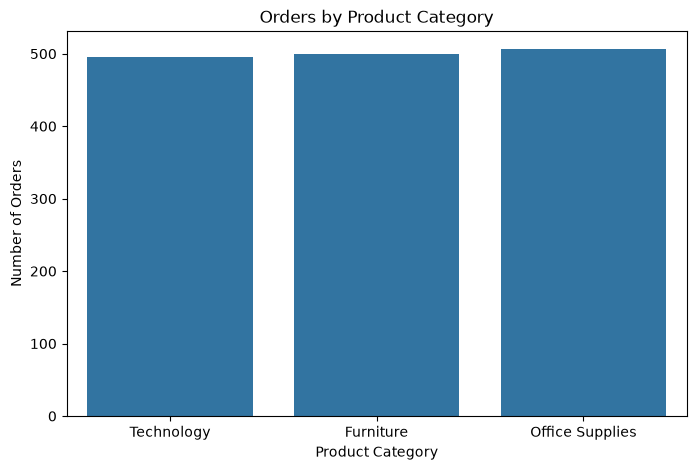

In [22]:
# task 8 customer and product 

plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Segment")

plt.title("Orders and customer")
plt.xlabel("Customer")
plt.ylabel("num of oders")
plt.show()

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Category")

plt.title("Orders by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")

plt.show()

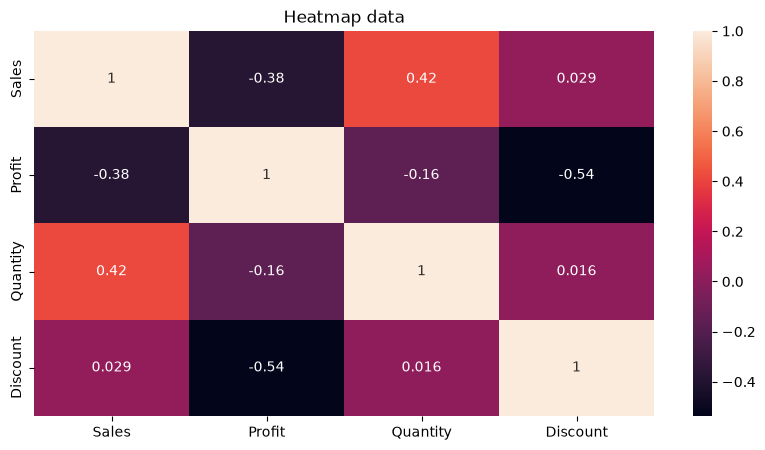

In [31]:
# Task 9 Correlation Analysis: Calculate the correlation matrix for Sales, Profit, Quantity, and Discount. Create a Seaborn heatmap with correlation values displayed inside each cell.

corr = df[["Sales","Profit","Quantity","Discount"]].corr()

plt.figure(figsize=(10,5))

sns.heatmap(corr,annot=True)

plt.title("Heatmap data")

plt.show()

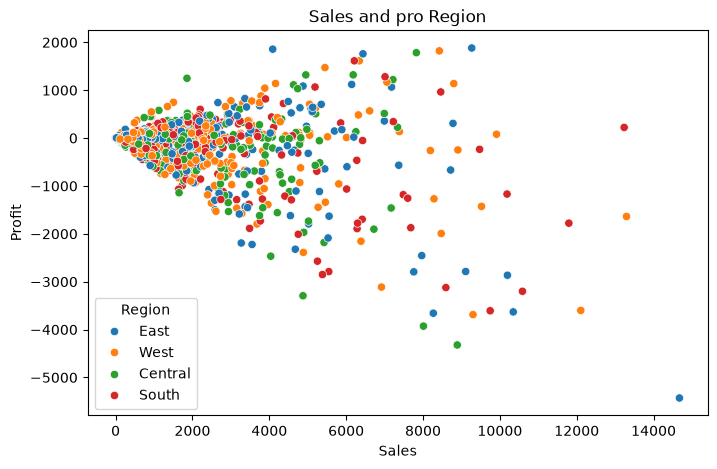

In [ ]:
#Task : 10 

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df,
                x="Sales",
                y="Profit",
                hue="Region")

plt.title("Sales and prof Region")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.legend(title="Region")

plt.show()


In [ ]:
plt.figure(figsize=(8, 5)) 

sns.regplot(data=df,)